# # A3 — Parallel Hybrid Digital Twin — Methanol Reactor
#
**Overview of the Approach:**
This notebook builds a "parallel hybrid digital twin" for a methanol reactor. 
 In simple terms, we use two different models in parallel: a first-principles physics model 
 and a machine learning (ML) model. Both models take the same plant inputs and predict the reactor's behavior. 
 Their predictions are then combined to give a final output. 
 The idea is to leverage the strengths of both approaches at the same time:
   - The physics model is grounded in established scientific understanding (e.g., ODEs based on reaction kinetics), 
     so it’s trustworthy for things like pressure and conversion.
   - The ML model is a flexible black box that can pick up on real-plant quirks from data, 
     often performing better for things like temperature profiles and heat transfer.
#
How the Parallel Strategy Works:**
Both models receive the same three key plant input variables.
Each model independently predicts the eight target reactor outputs.
For each output variable, we assign a "weight" (w_k) reflecting which approach is likely more reliable.
(For example, physics may get higher weight for pressure, ML for temperature.)
The final prediction for each output (ŷₖ) is a weighted sum:
ŷₖ = wₖ · y_phys,ₖ  +  (1−wₖ) · y_ML,ₖ

 In schematic form:
 ```text
#                  ┌─→ Physics ODE (η) → y_phys ─┐
# Plant inputs u ──┤                              ├─→ ŷₖ = wₖ·y_phys,ₖ + (1−wₖ)·y_ML,ₖ
#                  └─→ Black-box ML    → y_ML   ─┘
# ```
#
Why Use This Hybrid?**
By running the models in parallel and combining their outputs, 
we can often get more accurate and robust predictions than using either approach alone.
The model can "lean" more on physics where theory is strong and on ML where the data shows it can help.
#
 **Inputs & Outputs:**
#
 | Role           | Variables                                                       |
 |----------------|-----------------------------------------------------------------|
 | **Inputs (3)** | Inlet T (°C), Inlet P (bar_g), Methanol flow (kgmole/h)         |
 | **Outputs (8)**| Temp_0.2m … Temp_1m (°C), P_out (bar_g), Q (kW), Conversion (%) |

 **Reaction:** CH₃OH → CO + 2H₂  
 **Data Source:** `DATA.xlsx`

## 1. Imports

In [1]:
from pathlib import Path

# Import plotting, math, and data tools
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Import scientific Python tools for ODEs and optimization
from scipy.integrate import solve_ivp
from scipy.optimize import minimize_scalar

# Import scikit-learn for ML modeling and evaluation
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.multioutput import MultiOutputRegressor

# File path to data
DATA_FILE = Path("DATA.xlsx")
# Reactor measurement positions (in meters)
MEASUREMENT_POSITIONS_M = np.array([0.2, 0.4, 0.6, 0.8, 1.0])
# Atmospheric pressure (bar)
P_ATM_BAR = 1.01325

# Define columns for model input and output
INPUT_COLS = ["T_in_C", "P_in_bar_g", "F_in_kgmole_h"]
OUTPUT_COLS = [
    "T_0.2m_C", "T_0.4m_C", "T_0.6m_C", "T_0.8m_C", "T_1m_C",  # Temperatures at positions
    "P_out_bar_g",                # Outlet pressure
    "Q_total_kW",                 # Total heat input
    "X_overall_pct",              # Overall conversion
]
# Only temperature output columns
TEMP_COLS = ["T_0.2m_C", "T_0.4m_C", "T_0.6m_C", "T_0.8m_C", "T_1m_C"]

print("Libraries loaded.")
print("Data file:", DATA_FILE.resolve())

Libraries loaded.
Data file: C:\Users\krish\JBS Tech\Methanol Reforming\DATA.xlsx


## 2. Load and clean `DATA.xlsx`

In [2]:
def load_excel(path: Path) -> pd.DataFrame:
    # Load raw data from Excel file, using two header rows
    raw = pd.read_excel(path, sheet_name="Data", header=[0, 1])
    
    # Flatten multi-level column names; combine with unit if available
    raw.columns = [
        f"{name} ({unit})" if pd.notna(unit) and str(unit).strip() else str(name)
        for name, unit in raw.columns
    ]
    
    # Rename columns to short, friendly names
    data = raw.rename(
        columns={
            "Inlet Temperature (C)": "T_in_C",
            "Inlet Pressure (bar_g)": "P_in_bar_g",
            "Inlet molar flow rate (kgmole/h)": "F_in_kgmole_h",
            "Temp_0.2m (C)": "T_0.2m_C",
            "Temp_0.4m (C)": "T_0.4m_C",
            "Temp_0.6m (C)": "T_0.6m_C",
            "Temp_0.8m (C)": "T_0.8m_C",
            "Temp_1m (C)": "T_1m_C",
            "Outlet Pressure (bar_g)": "P_out_bar_g",
            "Total heat input (KW)": "Q_total_kW",
            "Overall Conversion (%)": "X_overall_pct",
        }
    )

    # Show counts of negative-valued rows in key columns
    n_raw = len(data)
    print("Negative-value scan:")
    print(f"  X_overall_pct : {(data['X_overall_pct'] < 0).sum()}")
    print(f"  P_out_bar_g   : {(data['P_out_bar_g'] < 0).sum()}")
    print(f"  Q_total_kW    : {(data['Q_total_kW'] < 0).sum()} (kept — sign convention)")

    # Build filter to keep only valid, physically meaningful rows
    ok = (
        data["X_overall_pct"].between(0, 5)  # conversion between 0 and 5%
        & data["P_out_bar_g"].ge(0)          # outlet pressure ≥ 0
        & data["P_in_bar_g"].ge(0)           # inlet pressure ≥ 0
        & data["F_in_kgmole_h"].gt(0)        # flow rate > 0
        & data["T_in_C"].ge(0)               # inlet temp ≥ 0
        & data[TEMP_COLS].ge(0).all(axis=1)  # all temperature columns ≥ 0
        & data["Q_total_kW"].between(-50, 50) # heat in plausible range
        & data[INPUT_COLS + OUTPUT_COLS].notna().all(axis=1)  # no NaNs in required cols
    )
    # Filter the data
    cleaned = data.loc[ok].reset_index(drop=True)
    print(f"Rows: {n_raw} raw → {len(cleaned)} after cleaning")
    return cleaned

# Load cleaned DataFrame and show first few rows
df = load_excel(DATA_FILE)
display(df[INPUT_COLS + OUTPUT_COLS].head())

Negative-value scan:
  X_overall_pct : 67
  P_out_bar_g   : 124
  Q_total_kW    : 1122 (kept — sign convention)
Rows: 1122 raw → 997 after cleaning


,T_in_C,P_in_bar_g,F_in_kgmole_h,T_0.2m_C,T_0.4m_C,T_0.6m_C,T_0.8m_C,T_1m_C,P_out_bar_g,Q_total_kW,X_overall_pct
0,200,0.4,0.10,113.6,125.2,135.9,145.5,154.1,0.3691,-0.7511,0.308629
1,200,0.4,0.35,115.0,114.7,118.4,122.7,126.8,0.2898,-0.8192,0.131113
2,200,0.4,0.60,120.2,116.4,117.7,120.1,122.8,0.1530,-0.9237,0.102860
3,200,0.8,0.10,113.4,125.0,135.8,145.4,154.1,0.7760,-0.7527,0.309011
4,200,0.8,0.35,114.7,114.4,118.2,122.5,126.7,0.7156,-0.8223,0.131407


## 3. Fixed reactor physics parameters

In [3]:
R = 8.314462618  # Universal gas constant (J/mol/K)

D = 0.1          # Reactor diameter (m)
L = 1.0          # Reactor length (m)
h_heat = 115.0   # Heat transfer coefficient (W/m2/K)
T_heat_C = 275.0 # Heating temperature (°C)
epsilon = 0.33   # Reactor void fraction
dp = 1.0e-3      # Particle diameter (m)
Ac = np.pi * D**2 / 4     # Reactor cross-sectional area (m2)
perimeter = np.pi * D     # Reactor perimeter (m)

# Molar masses (kg/mol)
MW_CH3OH = 32.04e-3   # Methanol
MW_CO = 28.01e-3      # Carbon monoxide
MW_H2 = 2.016e-3      # Hydrogen

# Heat capacities (J/mol/K)
Cp_CH3OH = 43.0
Cp_CO = 29.0
Cp_H2 = 29.0

# Kinetic parameters
A_kinetic = 7.0e10    # Pre-exponential factor for main reaction
E_kinetic = 19120.0   # Activation energy for main reaction (J/mol)
A_CO = 1.0e7          # Pre-exponential factor for CO adsorption
E_CO = 6036.8         # Activation energy for CO adsorption (J/mol)
delta_H = 90.5e3      # Reaction enthalpy change (J/mol)

ETA = 1.0             # Reaction efficiency (to be calibrated)

print(f"D={D} m, L={L} m, T_heat={T_heat_C} °C, ΔH={delta_H/1000:.1f} kJ/mol")

D=0.1 m, L=1.0 m, T_heat=275.0 °C, ΔH=90.5 kJ/mol


# ## 4. Physics ODE branch (parallel path 1)
# In this step, we define the physics-based path of our parallel digital twin by formulating and solving the system of ordinary differential equations (ODEs) that describe the plug flow reactor using first-principles chemical engineering models. This physics ODE branch serves as one of the parallel approaches used for comparison and hybridization with machine learning and other data-driven branches.

In [35]:
# Convert gauge pressure (bar_g) to absolute pressure in Pa
def bar_g_to_Pa(P_bar_g):
    return (P_bar_g + P_ATM_BAR) * 1.0e5

# Convert absolute pressure in Pa to gauge pressure (bar_g)
def Pa_to_bar_g(P_Pa):
    return P_Pa / 1.0e5 - P_ATM_BAR

# Convert flow rate from kgmole/h to mol/s
def kgmole_h_to_mol_s(F_kgmole_h):
    return F_kgmole_h * 1000.0 / 3600.0

# Calculate reaction rate using a simplified kinetic model
def reaction_rate(T_C, P, F_CH3OH, F_CO, F_H2, eta=None):
    if eta is None:
        eta = ETA
    T_abs = T_C + 273.15  # Convert temperature to Kelvin
    F_total = max(F_CH3OH + F_CO + F_H2, 1e-12) #Total molar flow rate
    C_total = P / (R * T_abs)  # Total concentration

    # Calculate the reaction rate using a simplified kinetic model:
    # r = (A * exp(-E/(RT)) * [CH3OH]) / (1 + A_CO * exp(-E_CO/(RT)) * [CO])
    # where concentrations are based on molar fractions and total concentration.
    C_CH3OH = (F_CH3OH / F_total) * C_total
    C_CO = (F_CO / F_total) * C_total
    num = A_kinetic * np.exp(-E_kinetic / (R * T_abs)) * C_CH3OH
    den = 1.0 + A_CO * np.exp(-E_CO / (R * T_abs)) * C_CO
    return eta * num / den

# ODE system for plug flow reactor model
#ETA= Reaction Efficiency
def reactor_model(z, y, eta=None):
    if eta is None:
        eta = ETA
    F_CH3OH = max(y[0], 1e-12)  # Methanol flow (avoid zero)
    F_CO = max(y[1], 0.0)       # CO flow
    F_H2 = max(y[2], 0.0)       # H2 flow
    T_C = y[3]                  # Temperature (°C)
    P = max(y[4], 1.0e3)        # Pressure (Pa)

    r = reaction_rate(T_C, P, F_CH3OH, F_CO, F_H2, eta=eta)  # Reaction rate
    rpl = r * Ac  # Reaction rate per length

    q_transfer = h_heat * perimeter * (T_heat_C - T_C)  # Heat transfer
    Cp_flow = max(F_CH3OH * Cp_CH3OH + F_CO * Cp_CO + F_H2 * Cp_H2, 1e-9)  # Heat capacity flow
    dT_dz = (q_transfer - delta_H * rpl) / Cp_flow  # Temp gradient

    F_total = F_CH3OH + F_CO + F_H2  # Total molar flow rate
    mass_flow = F_CH3OH * MW_CH3OH + F_CO * MW_CO + F_H2 * MW_H2  # Total mass flow rate
    MW_mix = mass_flow / max(F_total, 1e-12)  # Average molecular weight
    T_abs = T_C + 273.15  # Convert temperature to Kelvin
    rho = P * MW_mix / (R * T_abs)  # Density
    velocity = mass_flow / max(rho * Ac, 1e-12)  # Gas velocity
    mu = 2.0e-5  # Viscosity (fixed)
    # Pressure drop terms (Ergun equation)
    # Calculate pressure drop (Ergun equation)
    viscous = 150.0 * mu * (1.0 - epsilon) ** 2 / (epsilon ** 3 * dp ** 2) * velocity  # Viscous term
    inertial = 1.75 * rho * (1.0 - epsilon) / (epsilon ** 3 * dp) * velocity ** 2       # Inertial term
    dP_dz = -(viscous + inertial)  # Pressure drop

    return [-rpl, rpl, 2.0 * rpl, dT_dz, dP_dz, q_transfer]

# Simulate the physics model for a given set of conditions
def predict_physics(T_in_C, P_in_bar_g, F_in_kgmole_h, eta=None, n_points=80):
    if eta is None:
        eta = ETA
    F_in = kgmole_h_to_mol_s(F_in_kgmole_h)           # Input flow (mol/s)
    P_in_Pa = bar_g_to_Pa(P_in_bar_g)                 # Inlet pressure (Pa)
    y0 = [F_in, 0.0, 0.0, float(T_in_C), P_in_Pa, 0.0]  # Initial values
    z_eval = np.linspace(0.0, L, n_points)            # Axial positions

    
    # Solve ODEs
    # sol: Solution object from ODE solver (contains reactor profile)
    # solve_ivp: SciPy function to numerically solve the ODEs for reactor_model
    # lambda z, y: Reactor model ODEs as a function of position z and state y
    # z: Axial position along reactor
    # y: State variables [F_CH3OH, F_CO, F_H2, T_C, P, heat term]
    # eta: Reaction efficiency scaling parameter
    # (0.0, L): Integration span from reactor inlet (0.0 m) to outlet (L, reactor length)
    # y0: Initial state vector for ODE integration at reactor inlet
    # z_eval: Array of spatial positions to evaluate solution/profile
    # method="BDF": Use backward differentiation method for stiff problems
    # rtol=1e-5: Relative tolerance for ODE solver
    # atol=1e-8: Absolute tolerance for ODE solver
    sol = solve_ivp(
        lambda z, y: reactor_model(z, y, eta=eta),
        (0.0, L),
        y0,
        t_eval=z_eval,
        method="BDF",
        rtol=1e-5,
        atol=1e-8,
    )
    if not sol.success:
        raise RuntimeError(sol.message)

    F_out = float(sol.y[0, -1])                # Outlet methanol flow
    T_profile = sol.y[3]                       # Temperature profile
    T_axial = np.interp(MEASUREMENT_POSITIONS_M, sol.t, T_profile)  # Values at measured positions
    X_pct = (F_in - F_out) / F_in * 100.0      # Conversion, %

    return {
        "T_0.2m_C": float(T_axial[0]),
        "T_0.4m_C": float(T_axial[1]),
        "T_0.6m_C": float(T_axial[2]),
        "T_0.8m_C": float(T_axial[3]),
        "T_1m_C": float(T_axial[4]),
        "P_out_bar_g": float(Pa_to_bar_g(sol.y[4, -1])),
        "Q_total_kW": float(sol.y[5, -1] / 1000.0),
        "X_overall_pct": float(X_pct),
        "z_m": sol.t,
        "T_profile_C": T_profile,
    }

# Make prediction as a vector of output variables
def physics_vector(T_in_C, P_in_bar_g, F_in_kgmole_h, eta=None):
    p = predict_physics(T_in_C, P_in_bar_g, F_in_kgmole_h, eta=eta)
    return np.array([p[c] for c in OUTPUT_COLS], dtype=float)

print("Physics branch ready.")

Physics branch ready.


## 5. Train / test split

In [17]:
# Split the DataFrame into training and test sets (80% train, 20% test)
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)

# Reset index so the row numbers go from 0...N-1 in each set
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# Print how many rows are in the training and test sets
print(f"Train rows: {len(train_df)}")
print(f"Test rows : {len(test_df)}")

Train rows: 797
Test rows : 200


# 6. Calibrate physics rate scale η
#
 In this step, we calibrate the adjustable rate scale parameter η (eta) in the physics-based model. 
 The goal is to align the physics model's conversion predictions (X_overall_pct) as closely as possible 
 to the observed Excel dataset values, before introducing any blending with machine learning outputs. 
 We accomplish this by searching for a value of η that minimizes the mean squared error (MSE) between 
 the model’s predictions and the Excel values for "overall conversion" using a subset of the training data. 
 This calibration ensures a fairer and more meaningful comparison between the purely physics-based, 
 machine-learning-only, and hybrid (parallel) approaches in the following steps.

In [20]:
def calibrate_eta(df_train, n_cases=40):
    # Sample a subset of the training data
    sample = df_train.sample(n=min(n_cases, len(df_train)), random_state=42)
    first_error = None

    def objective(log_eta):
        # Calculate error between physics prediction and Excel output for X_overall_pct
        eta = 10 ** log_eta
        errs = []
        for _, row in sample.iterrows():
            try:
                # Get physics model prediction
                pred = physics_vector(row["T_in_C"], row["P_in_bar_g"], row["F_in_kgmole_h"], eta=eta)
                # Compute squared error on the last output (X_overall_pct)
                errs.append((pred[-1] - row["X_overall_pct"]) ** 2)
            except Exception as exc:
                # If physics fails, count error as very large
                if first_error is None:
                    first_error = exc
                errs.append(1e6)
        return np.mean(errs)

    print("Calibrating eta...")
    # Search for log10(eta) that minimizes mean squared error
    result = minimize_scalar(
        objective, bounds=(-10.0, -4.0), method="bounded", options={"xatol": 0.05}
    )
    # If all runs failed, raise an error
    if first_error is not None and result.fun >= 1.0e6:
        raise RuntimeError(
            f"Eta calibration failed for all sample cases. First physics error: {first_error!r}. "
            "Re-run Step 4 (physics ODE) and Step 5 (train/test split), then this cell."
        )
    # Return best eta and corresponding error
    return float(10 ** result.x), float(result.fun)


ETA, eta_obj = calibrate_eta(train_df, n_cases=40)
print(f"Calibrated ETA = {ETA:.6e}  (sample conversion MSE = {eta_obj:.4f})")


Calibrating eta...
Calibrated ETA = 1.001097e-07  (sample conversion MSE = 0.0024)


# 7. Run the physics-based model on both the training and test datasets to generate physics-only predictions for later comparison and blending.

In [22]:
def run_physics_matrix(data, eta, label="set"):
    # Go through each row and run the physics model. If one fails, continue.
    rows = []
    n_fail = 0        # Count failures
    first_error = None  # Remember the first error

    for _, row in data.iterrows():
        try:
            # Run the physics model for this row
            rows.append(
                physics_vector(
                    row["T_in_C"], row["P_in_bar_g"], row["F_in_kgmole_h"], eta=eta
                )
            )
        except Exception as exc:
            # If it fails, record the error and fill with NaNs
            n_fail += 1
            if first_error is None:
                first_error = exc
            rows.append(np.full(len(OUTPUT_COLS), np.nan))

        # Print progress every 100 rows
        if (len(rows) % 100) == 0:
            print(f"  {label}: {len(rows)}/{len(data)}")

    if first_error is not None:
        # Warn if there were any failures
        print(f"  WARNING [{label}]: {n_fail} physics failures. First error: {first_error!r}")

    # Stack all the results into an array
    return np.vstack(rows)


print("Physics on train...")

# Y_phys_train: NumPy array of physics model predictions for the training set (shape: n_train_samples x n_outputs)
Y_phys_train = run_physics_matrix(train_df, ETA, label="train")

print("Physics on test...")

# Y_phys_test: NumPy array of physics model predictions for the test set (shape: n_test_samples x n_outputs)
Y_phys_test = run_physics_matrix(test_df, ETA, label="test")

# U_train: NumPy array of input features for training set (shape: n_train_samples x n_input_features)
U_train = train_df[INPUT_COLS].to_numpy(dtype=float)

# U_test: NumPy array of input features for test set (shape: n_test_samples x n_input_features)
U_test = test_df[INPUT_COLS].to_numpy(dtype=float)

# Y_excel_train: NumPy array of true output values ("Excel" ground truth) for training set (shape: n_train_samples x n_outputs)
Y_excel_train = train_df[OUTPUT_COLS].to_numpy(dtype=float)

# Y_excel_test: NumPy array of true output values ("Excel" ground truth) for test set (shape: n_test_samples x n_outputs)
Y_excel_test = test_df[OUTPUT_COLS].to_numpy(dtype=float)

# ok_train: Boolean array indicating which training samples produced finite outputs from the physics model
ok_train = np.isfinite(Y_phys_train).all(axis=1)

# ok_test: Boolean array indicating which test samples produced finite outputs from the physics model
ok_test = np.isfinite(Y_phys_test).all(axis=1)

print(f"Finite physics — train {ok_train.sum()}/{len(ok_train)}, test {ok_test.sum()}/{len(ok_test)}")

if ok_train.sum() == 0:
    raise RuntimeError(
        "All physics predictions failed. Re-run Steps 4-6 first "
        "(physics functions + train/test split + eta calibration)."
    )


Physics on train...
  train: 100/797
  train: 200/797
  train: 300/797
  train: 400/797
  train: 500/797
  train: 600/797
  train: 700/797
Physics on test...
  test: 100/200
  test: 200/200
Finite physics — train 797/797, test 200/200


## 8. ML branch (parallel path 2)

Black-box model: **only plant inputs → 8 outputs** (does not see physics outputs).

In [24]:
# ML branch uses plant inputs only (parallel to physics).
# Train on the FULL Excel train set — not on physics-filtered rows.
ml_model = MultiOutputRegressor(
    HistGradientBoostingRegressor(
        max_depth=6,
        learning_rate=0.08,
        max_iter=250,

        l2_regularization=0.1,
        random_state=42,
    )
)
ml_model.fit(U_train, Y_excel_train)
print("ML branch trained (u -> 8 outputs).")

# Predict ML model outputs for training and test sets (NumPy arrays, shape: n_samples x n_outputs)
Y_ml_train = ml_model.predict(U_train)  # ML predictions for training set inputs
Y_ml_test = ml_model.predict(U_test)    # ML predictions for test set inputs
print(f"Y_ml_train shape: {Y_ml_train.shape}, Y_ml_test shape: {Y_ml_test.shape}")


ML branch trained (u -> 8 outputs).
Y_ml_train shape: (797, 8), Y_ml_test shape: (200, 8)


# 9. Parallel combiner — learn optimal blend weight `w_k` per output
#
In this step, we combine the predictions from both the physics-based model and the machine learning (ML) model
 using a weighted average. For each output variable `k`, we assign a weight `w_k` to the physics model and `(1 - w_k)`
to the ML model:

```text
ŷ_k = w_k · y_phys,k + (1 − w_k) · y_ML,k
```

Here:
- `ŷ_k`: The combined (parallel) prediction for output `k`
- `y_phys,k`: The physics model's prediction for output `k`
- `y_ML,k`: The ML model's prediction for output `k`
- `w_k`: The learned weight (between 0 and 1) blending the two predictions

Interpretation of weights:
- `w_k = 1` → the final prediction depends entirely on the physics model for that output
- `w_k = 0` → the final prediction depends entirely on the ML model for that output

The key idea is to **learn each `w_k` automatically** based on how well each model matches the actual Excel plant data on the training set.
For each output, we select the value of `w_k` that minimizes the _mean absolute error_ (MAE) of the combined prediction vs. the Excel “ground truth” on the training samples where the physics model succeeded.

This allows the combiner to favor the model (physics or ML) that is more accurate for each output, or use a blend if that is better.

In [31]:
# ---- Parallel Hybrid Combiner Step ----

# Learn the optimal blend weight between physics and ML predictions for each output
def best_weight(y_phys_col, y_ml_col, y_excel_col):
    # For a single output: find w in [0,1] that minimizes the mean absolute error between
    # the weighted average of physics and ML predictions versus Excel (ground truth)
    def mae(w):
        y_hat = w * y_phys_col + (1.0 - w) * y_ml_col
        return mean_absolute_error(y_excel_col, y_hat)
    result = minimize_scalar(mae, bounds=(0.0, 1.0), method="bounded")
    return float(result.x), float(result.fun)

# Helper to keep model outputs in feasible ranges
def clip_parallel(y, P_in_bar_g):
    out = y.copy()
    out[0:5] = np.clip(out[0:5], 0.0, 800.0)      # limit temp outputs
    out[5] = min(float(out[5]), float(P_in_bar_g) - 1e-6)   # limit pressure out
    out[7] = np.clip(out[7], 0.0, 100.0)          # limit conversion to 0-100%
    return out

# Prepare data, keeping only rows where physics-based model succeeded
# Define training set variables where physics-based model succeeded
U_tr = U_train[ok_train]          # Inputs for successful training points
Yp_tr = Y_phys_train[ok_train]    # Physics-based model predictions
Ym_tr = Y_ml_train[ok_train]      # ML model predictions
Ye_tr = Y_excel_train[ok_train]   # Excel (ground truth) outputs

# Find best blend weights for each output
# This step determines, for each output variable, the optimal weight to blend 
# between the physics-based model and the machine learning (ML) model predictions.
# It does this by finding the value of w (between 0 and 1) 
# that minimizes the mean absolute error (MAE) between the blended prediction
# and the actual Excel ground truth, using only the training data where the physics model produced valid results.
# The learned weights show, for each output, whether the final parallel prediction 
# relies more on the physics model or the ML model, or is some blend of the two.
W = np.zeros(len(OUTPUT_COLS))
weight_rows = []
for k, col in enumerate(OUTPUT_COLS):
    # Define best_weight function
    def best_weight(y_phys_col, y_ml_col, y_excel_col):
        """
        For a single output variable, find the optimal blending weight w in [0, 1]
        that minimizes the mean absolute error (MAE) between a weighted combination
        of physics and ML predictions and the Excel ground truth.

        Returns:
            w_opt: optimal blending weight for the physics model
            mae_opt: achieved MAE at w_opt
        """
        def mae(w):
            y_hat = w * y_phys_col + (1.0 - w) * y_ml_col
            return mean_absolute_error(y_excel_col, y_hat)
        result = minimize_scalar(mae, bounds=(0.0, 1.0), method="bounded")
        return float(result.x), float(result.fun)
    
    w_k, mae_k = best_weight(Yp_tr[:, k], Ym_tr[:, k], Ye_tr[:, k])
    W[k] = w_k
    weight_rows.append({
        "Output": col,
        "w_physics": w_k,
        "w_ML": 1.0 - w_k,
        "train MAE at w*": mae_k,
        "leans toward": "physics" if w_k >= 0.5 else "ML",
    })

# Show learned weights
weights_table = pd.DataFrame(weight_rows)
print("Learned parallel blend weights (train):")
display(weights_table.round(4))

# Weighted average combiner for batch predictions
def combine_parallel(Y_phys, Y_ml, weights=W):
    # Compute: y_hat = w * y_phys + (1-w) * y_ML for each output
    return weights * Y_phys + (1.0 - weights) * Y_ml

# Make final hybrid predictions
# - Where physics predictions are valid, blend the models
# - Where physics is NaN, fall back to ML
Y_par_train = np.where(
    np.isfinite(Y_phys_train),
    combine_parallel(Y_phys_train, Y_ml_train),
    Y_ml_train,
)
Y_par_test = np.where(
    np.isfinite(Y_phys_test),
    combine_parallel(Y_phys_test, Y_ml_test),
    Y_ml_test,
)

# Post-process predictions to enforce physical limits for each test sample
for i in range(len(U_test)):
    Y_par_test[i] = clip_parallel(Y_par_test[i], P_in_bar_g=U_test[i, 1])

print("Parallel predictions ready.")


Learned parallel blend weights (train):


,Output,w_physics,w_ML,train MAE at w*,leans toward
0,T_0.2m_C,0.0001,0.9999,0.1580,ML
1,T_0.4m_C,0.0000,1.0000,0.1145,ML
2,T_0.6m_C,0.0001,0.9999,0.1162,ML
3,T_0.8m_C,0.0000,1.0000,0.1155,ML
4,T_1m_C,0.0000,1.0000,0.1061,ML
5,P_out_bar_g,0.0093,0.9907,0.0104,ML
6,Q_total_kW,0.0000,1.0000,0.0010,ML
7,X_overall_pct,0.0000,1.0000,0.0007,ML


Parallel predictions ready.


## 10. Validate: physics vs ML vs parallel (test set)

,Output,MAE physics,MAE ML-only,MAE parallel,R2 parallel,w_physics
0,T_0.2m_C,152.4008,0.2091,0.2066,0.9999,0.0001
1,T_0.4m_C,146.0001,0.1641,0.1641,0.9998,0.0000
2,T_0.6m_C,139.7063,0.1457,0.1448,0.9998,0.0001
3,T_0.8m_C,134.5783,0.1378,0.1378,0.9998,0.0000
4,T_1m_C,130.3583,0.1322,0.1322,0.9998,0.0000
5,P_out_bar_g,0.0867,0.0156,0.0155,0.9994,0.0093
6,Q_total_kW,0.8748,0.0013,0.0013,0.9998,0.0000
7,X_overall_pct,0.0503,0.0008,0.0008,0.9999,0.0000


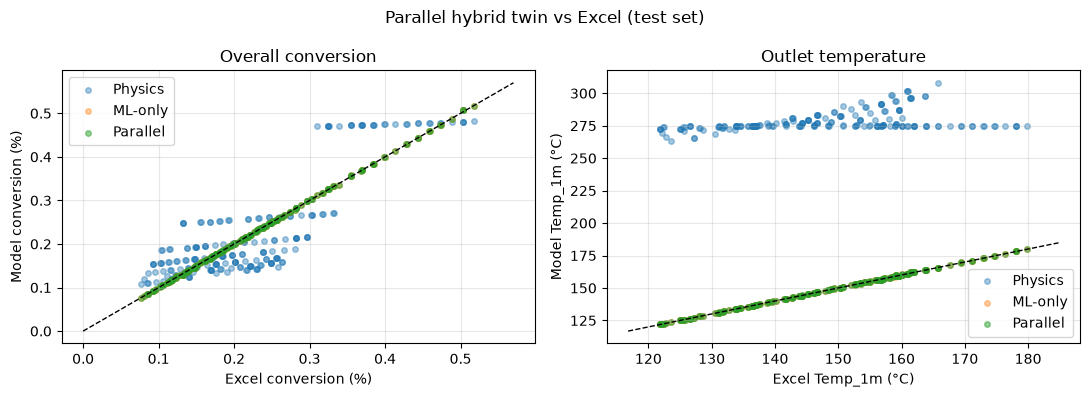

In [32]:
rows = []
for i, col in enumerate(OUTPUT_COLS):
    rows.append({
        "Output": col,
        "MAE physics": mean_absolute_error(Y_excel_test[:, i], Y_phys_test[:, i]),
        "MAE ML-only": mean_absolute_error(Y_excel_test[:, i], Y_ml_test[:, i]),
        "MAE parallel": mean_absolute_error(Y_excel_test[:, i], Y_par_test[:, i]),
        "R2 parallel": r2_score(Y_excel_test[:, i], Y_par_test[:, i]),
        "w_physics": W[i],
    })

metrics = pd.DataFrame(rows)
display(metrics.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].scatter(Y_excel_test[:, 7], Y_phys_test[:, 7], alpha=0.4, s=16, label="Physics")
axes[0].scatter(Y_excel_test[:, 7], Y_ml_test[:, 7], alpha=0.4, s=16, label="ML-only")
axes[0].scatter(Y_excel_test[:, 7], Y_par_test[:, 7], alpha=0.5, s=16, label="Parallel")
lim = max(Y_excel_test[:, 7].max(), Y_par_test[:, 7].max(), 1e-6) * 1.1
axes[0].plot([0, lim], [0, lim], "k--", lw=1)
axes[0].set_xlabel("Excel conversion (%)")
axes[0].set_ylabel("Model conversion (%)")
axes[0].set_title("Overall conversion")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].scatter(Y_excel_test[:, 4], Y_phys_test[:, 4], alpha=0.4, s=16, label="Physics")
axes[1].scatter(Y_excel_test[:, 4], Y_ml_test[:, 4], alpha=0.4, s=16, label="ML-only")
axes[1].scatter(Y_excel_test[:, 4], Y_par_test[:, 4], alpha=0.5, s=16, label="Parallel")
t0 = min(Y_excel_test[:, 4].min(), Y_par_test[:, 4].min()) - 5
t1 = max(Y_excel_test[:, 4].max(), Y_par_test[:, 4].max()) + 5
axes[1].plot([t0, t1], [t0, t1], "k--", lw=1)
axes[1].set_xlabel("Excel Temp_1m (°C)")
axes[1].set_ylabel("Model Temp_1m (°C)")
axes[1].set_title("Outlet temperature")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

fig.suptitle("Parallel hybrid twin vs Excel (test set)")
fig.tight_layout()
plt.show()

## 11. Digital twin function

`predict_outputs(T_in, P_in, F_in)` runs **both** branches and blends with learned weights.

In [33]:
def predict_outputs(T_in_C, P_in_bar_g, F_in_kgmole_h):
    """
    Parallel digital twin: 3 inputs → 8 blended outputs.

      y_phys = ODE(η)
      y_ML   = ML(u)
      ŷ      = w ⊙ y_phys + (1−w) ⊙ y_ML
    """
    phys = predict_physics(T_in_C, P_in_bar_g, F_in_kgmole_h, eta=ETA)
    y_phys = np.array([phys[c] for c in OUTPUT_COLS], dtype=float)

    u = np.array([[T_in_C, P_in_bar_g, F_in_kgmole_h]], dtype=float)
    y_ml = ml_model.predict(u)[0]

    y_hat = combine_parallel(y_phys, y_ml, weights=W)
    y_hat = clip_parallel(y_hat, P_in_bar_g=P_in_bar_g)

    out = {c: float(y_hat[i]) for i, c in enumerate(OUTPUT_COLS)}
    out["y_phys"] = {c: float(y_phys[i]) for i, c in enumerate(OUTPUT_COLS)}
    out["y_ml"] = {c: float(y_ml[i]) for i, c in enumerate(OUTPUT_COLS)}
    out["w_physics"] = {c: float(W[i]) for i, c in enumerate(OUTPUT_COLS)}
    out["z_m"] = phys["z_m"]
    out["T_profile_C"] = phys["T_profile_C"]
    return out


demo = df.iloc[0]
demo_pred = predict_outputs(demo["T_in_C"], demo["P_in_bar_g"], demo["F_in_kgmole_h"])

smoke = pd.DataFrame({
    "Output": OUTPUT_COLS,
    "Excel": [demo[c] for c in OUTPUT_COLS],
    "Physics": [demo_pred["y_phys"][c] for c in OUTPUT_COLS],
    "ML-only": [demo_pred["y_ml"][c] for c in OUTPUT_COLS],
    "Parallel": [demo_pred[c] for c in OUTPUT_COLS],
    "w_phys": [demo_pred["w_physics"][c] for c in OUTPUT_COLS],
})
smoke["Abs error"] = (smoke["Parallel"] - smoke["Excel"]).abs()
print("Smoke test — first cleaned DATA.xlsx row:")
display(smoke.round(4))

Smoke test — first cleaned DATA.xlsx row:


,Output,Excel,Physics,ML-only,Parallel,w_phys,Abs error
0,T_0.2m_C,113.6000,274.3918,113.7011,113.7182,0.0001,0.1182
1,T_0.4m_C,125.2000,274.7219,124.8928,124.8937,0.0000,0.3063
2,T_0.6m_C,135.9000,274.7787,136.1667,136.1756,0.0001,0.2756
3,T_0.8m_C,145.5000,274.8106,145.8372,145.8380,0.0000,0.3380
4,T_1m_C,154.1000,274.8317,154.5350,154.5357,0.0000,0.4357
5,P_out_bar_g,0.3691,0.3522,0.3793,0.3790,0.0093,0.0099
6,Q_total_kW,-0.7511,0.1013,-0.7551,-0.7551,0.0000,0.0040
7,X_overall_pct,0.3086,0.4697,0.3111,0.3111,0.0000,0.0025


---

## 12. Interactive digital twin

Enter the 3 plant inputs. Type `q` to quit. Press Enter for defaults.


  METHANOL REACTOR — PARALLEL HYBRID DIGITAL TWIN
  ŷ = w·y_phys + (1−w)·y_ML   (per-output weights)
  Physics η = 1.001097e-07
  Press Enter for defaults. Type q to stop.


--------------------------------------------------------------
INPUTS
  Inlet Temperature     : 200.00 °C
  Inlet Pressure        : 0.4000 bar_g
  Methanol flow         : 0.1000 kgmole/h

PARALLEL TWIN OUTPUTS
  Temp_0.2m             : 113.72 °C
  Temp_0.4m             : 124.89 °C
  Temp_0.6m             : 136.18 °C
  Temp_0.8m             : 145.84 °C
  Temp_1m (outlet)      : 154.54 °C
  Outlet Pressure       : 0.3790 bar_g
  Total heat input      : -0.7551 kW
  Overall Conversion    : 0.3111 %
--------------------------------------------------------------


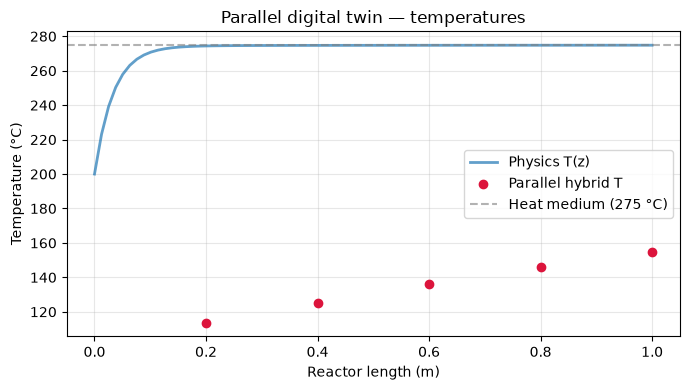

Digital twin stopped.


In [34]:
def _ask_float(prompt, default=None):
    hint = f" [{default}]" if default is not None else ""
    while True:
        raw = input(f"{prompt}{hint}: ").strip()
        if raw.lower() in {"q", "quit", "exit"}:
            return None
        if raw == "" and default is not None:
            return float(default)
        try:
            return float(raw)
        except ValueError:
            print("  Please enter a number (or q to quit).")


def run_digital_twin_interactive():
    print("\n" + "=" * 62)
    print("  METHANOL REACTOR — PARALLEL HYBRID DIGITAL TWIN")
    print("  ŷ = w·y_phys + (1−w)·y_ML   (per-output weights)")
    print("=" * 62)
    print(f"  Physics η = {ETA:.6e}")
    print("  Press Enter for defaults. Type q to stop.\n")

    while True:
        T_in_C = _ask_float("Inlet temperature [°C]", default=200.0)
        if T_in_C is None:
            print("Digital twin stopped.")
            break

        P_in_bar_g = _ask_float("Inlet pressure [bar_g]", default=0.4)
        if P_in_bar_g is None:
            print("Digital twin stopped.")
            break

        F_in_kgmole_h = _ask_float("Methanol molar flow [kgmole/h]", default=0.1)
        if F_in_kgmole_h is None:
            print("Digital twin stopped.")
            break

        if F_in_kgmole_h <= 0:
            print("  Flow must be > 0. Try again.\n")
            continue

        try:
            pred = predict_outputs(T_in_C, P_in_bar_g, F_in_kgmole_h)
        except Exception as exc:
            print(f"  Prediction failed: {exc}\n")
            continue

        print("\n" + "-" * 62)
        print("INPUTS")
        print(f"  Inlet Temperature     : {T_in_C:.2f} °C")
        print(f"  Inlet Pressure        : {P_in_bar_g:.4f} bar_g")
        print(f"  Methanol flow         : {F_in_kgmole_h:.4f} kgmole/h")
        print("\nPARALLEL TWIN OUTPUTS")
        print(f"  Temp_0.2m             : {pred['T_0.2m_C']:.2f} °C")
        print(f"  Temp_0.4m             : {pred['T_0.4m_C']:.2f} °C")
        print(f"  Temp_0.6m             : {pred['T_0.6m_C']:.2f} °C")
        print(f"  Temp_0.8m             : {pred['T_0.8m_C']:.2f} °C")
        print(f"  Temp_1m (outlet)      : {pred['T_1m_C']:.2f} °C")
        print(f"  Outlet Pressure       : {pred['P_out_bar_g']:.4f} bar_g")
        print(f"  Total heat input      : {pred['Q_total_kW']:.4f} kW")
        print(f"  Overall Conversion    : {pred['X_overall_pct']:.4f} %")
        print("-" * 62)

        fig, ax = plt.subplots(figsize=(7, 4))
        ax.plot(pred["z_m"], pred["T_profile_C"], lw=2, alpha=0.7, label="Physics T(z)")
        ax.scatter(
            MEASUREMENT_POSITIONS_M,
            [pred[c] for c in TEMP_COLS],
            color="crimson", zorder=5, label="Parallel hybrid T",
        )
        ax.axhline(T_heat_C, color="gray", ls="--", alpha=0.6, label=f"Heat medium ({T_heat_C:.0f} °C)")
        ax.set_xlabel("Reactor length (m)")
        ax.set_ylabel("Temperature (°C)")
        ax.set_title("Parallel digital twin — temperatures")
        ax.legend()
        ax.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

        again = input("\nRun another case? [Y/n]: ").strip().lower()
        if again in {"n", "no", "q", "quit"}:
            print("Digital twin stopped.")
            break


run_digital_twin_interactive()